# 01 · Visão inicial dos dados

Primeiro contato com `data/processed/games_scores.parquet`: o tamanho do dataset, o target
(`igdb_critic_score`), a confiabilidade dele pelo número de críticos, a cobertura no tempo e
as primeiras features candidatas.

**Base da modelagem:** jogos lançados com **mais de 3 críticos** (`igdb_critic_n >= 4`) e
**lançados depois de 2009** (`release_year >= 2010`). As seções 2 a 4 mostram o dataset
inteiro para justificar o recorte; da seção 5 em diante, só a base entra.

**Lembrete de vazamento:** `igdb_critic_*`, `oc_*` e `mc_*` são pós-lançamento. Aqui aparecem
só para descrever o target, nunca como feature.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_parquet(ROOT / "data/processed/games_scores.parquet")

MIN_CRITICS, MIN_YEAR = 4, 2010  # mais de 3 críticos, lançados depois de 2009

released = df[~df["is_upcoming"]].copy()
upcoming = df[df["is_upcoming"]].copy()
released["confiavel"] = released["igdb_critic_n"] >= MIN_CRITICS
base = released[released["confiavel"] & (released["release_year"] >= MIN_YEAR)].copy()

pd.set_option("display.max_columns", 50)
print(f"{len(df):,} jogos | {len(released):,} lançados com target | {len(upcoming):,} por lançar")
print(f"base da modelagem ({MIN_CRITICS}+ críticos, {MIN_YEAR}+): {len(base):,} jogos")

21,936 jogos | 14,734 lançados com target | 7,202 por lançar
base da modelagem (4+ críticos, 2010+): 3,157 jogos


In [2]:
# Estilo dos gráficos: superfície clara, grade discreta, uma cor por papel
BLUE, BLUE_LIGHT, ORANGE = "#2a78d6", "#9ec5f4", "#eb6834"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "figure.figsize": (9, 4.2),
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.labelcolor": INK_2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "legend.frameon": False, "lines.linewidth": 2,
})

## 1. O que tem no dataset

Fração preenchida de cada coluna nos jogos lançados. Colunas pouco preenchidas viram features
fracas ou precisam de um tratamento explícito para o valor ausente.

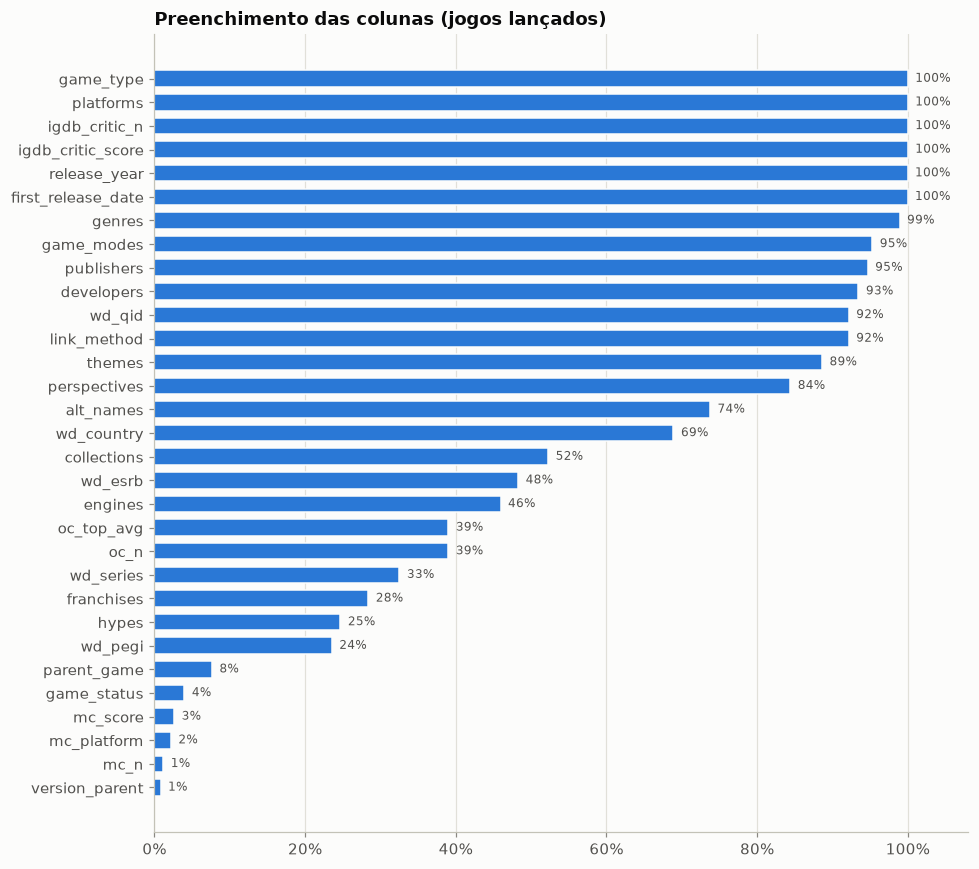

In [3]:
fill = released.notna().mean().sort_values()
fill = fill[~fill.index.isin(["igdb_id", "name", "slug", "is_upcoming", "confiavel"])]

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(fill.index, fill.values, color=BLUE, height=0.7, edgecolor="#fcfcfb", linewidth=1)
ax.set_xlim(0, 1.08)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for y, v in enumerate(fill.values):
    ax.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=8, color=INK_2)
ax.set_title("Preenchimento das colunas (jogos lançados)")
plt.tight_layout(); plt.show()

## 2. O target: `igdb_critic_score`

A distribuição geral e, separada, a da base da modelagem.

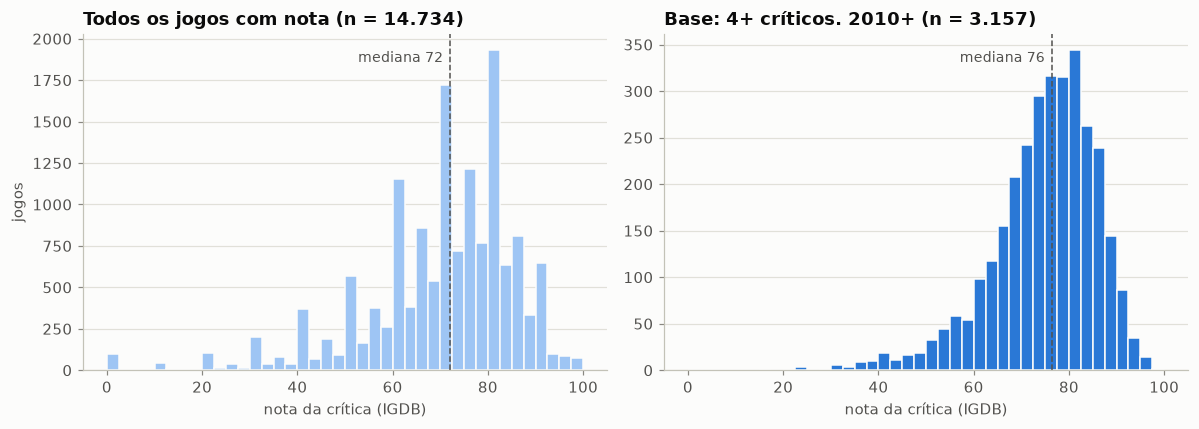

count    14734.0
mean        69.5
std         16.0
min          0.0
25%         60.3
50%         72.1
75%         80.0
max        100.0
Name: igdb_critic_score, dtype: float64

In [4]:
bins = np.arange(0, 101, 2.5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, (label, sub, color) in zip(axes, [
    ("Todos os jogos com nota", released, BLUE_LIGHT),
    (f"Base: {MIN_CRITICS}+ críticos, {MIN_YEAR}+", base, BLUE),
]):
    y = sub["igdb_critic_score"]
    ax.hist(y, bins=bins, color=color, edgecolor="#fcfcfb", linewidth=1)
    ax.axvline(y.median(), color=INK_2, linewidth=1, linestyle="--")
    ax.text(y.median() - 1.5, ax.get_ylim()[1] * 0.95, f"mediana {y.median():.0f}", color=INK_2, fontsize=9,
            ha="right", va="top", bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1))
    ax.set_title(f"{label} (n = {len(y):,})".replace(",", "."))
    ax.set_xlabel("nota da crítica (IGDB)")
axes[0].set_ylabel("jogos")
plt.tight_layout(); plt.show()

released["igdb_critic_score"].describe().round(1)

## 3. Confiabilidade do target pelo número de críticos

Com poucos críticos a nota oscila mais. A comparação com o OpenCritic (mesmo jogo, outra
fonte) mostra quanto: o erro cai conforme o número de críticos sobe.
3 e 4 críticos aparecem separados porque o corte passa entre eles.

,jogos,correlação,erro_abs_mediano
faixa_n,,,
1,1615.0,0.57,7.00
2,1007.0,0.79,4.50
3,736.0,0.84,4.00
4,518.0,0.89,3.25
5–9,1187.0,0.93,2.67
10+,687.0,0.95,1.78


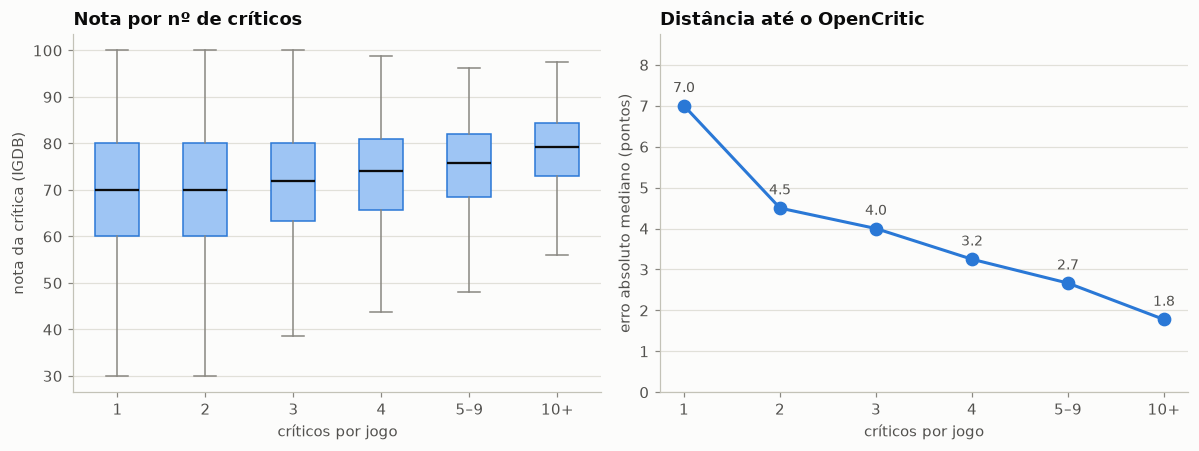

In [5]:
cuts = [-1, 1, 2, 3, 4, 9, 10**6]
labels = ["1", "2", "3", "4", "5–9", "10+"]
released["faixa_n"] = pd.cut(released["igdb_critic_n"], cuts, labels=labels)

both = released.dropna(subset=["oc_top_avg"])
quality = both.groupby("faixa_n", observed=True).apply(
    lambda g: pd.Series({
        "jogos": len(g),
        "correlação": g["igdb_critic_score"].corr(g["oc_top_avg"]),
        "erro_abs_mediano": (g["igdb_critic_score"] - g["oc_top_avg"]).abs().median(),
    }), include_groups=False)
display(quality.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
groups = [released.loc[released["faixa_n"] == l, "igdb_critic_score"] for l in labels]
bp = ax.boxplot(groups, tick_labels=labels, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, linewidth=1.5),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch in bp["boxes"]:
    patch.set(facecolor=BLUE_LIGHT, edgecolor=BLUE)
ax.set_title("Nota por nº de críticos")
ax.set_xlabel("críticos por jogo"); ax.set_ylabel("nota da crítica (IGDB)")

ax = axes[1]
ax.plot(quality.index.astype(str), quality["erro_abs_mediano"], color=BLUE, marker="o", markersize=8)
for x, v in zip(quality.index.astype(str), quality["erro_abs_mediano"]):
    ax.annotate(f"{v:.1f}", (x, v), textcoords="offset points", xytext=(0, 9), ha="center",
                fontsize=9, color=INK_2)
ax.set_ylim(0, quality["erro_abs_mediano"].max() * 1.25)
ax.set_title("Distância até o OpenCritic")
ax.set_xlabel("críticos por jogo"); ax.set_ylabel("erro absoluto mediano (pontos)")
plt.tight_layout(); plt.show()

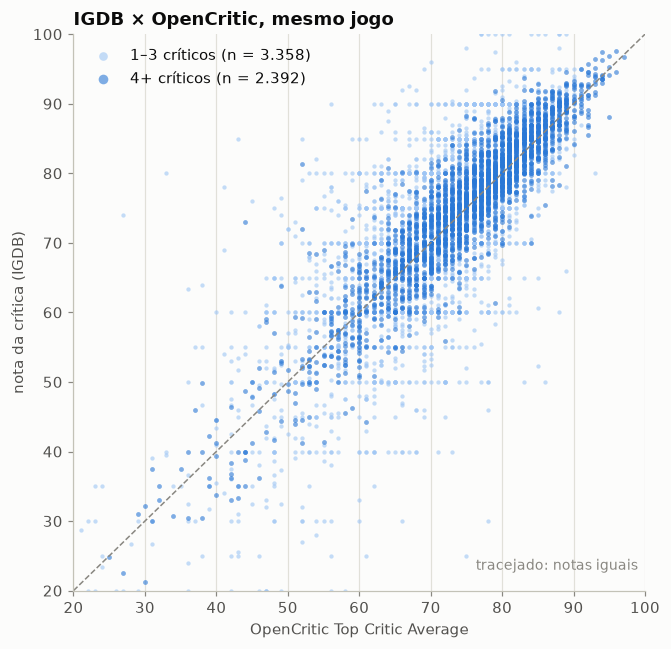

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 6))
for flag, color, label, size in [(False, BLUE_LIGHT, f"1–{MIN_CRITICS - 1} críticos", 8), (True, BLUE, f"{MIN_CRITICS}+ críticos", 10)]:
    s = both[both["confiavel"] == flag]
    ax.scatter(s["oc_top_avg"], s["igdb_critic_score"], s=size, color=color, alpha=0.6,
               linewidths=0, label=f"{label} (n = {len(s):,})".replace(",", "."))
ax.plot([20, 100], [20, 100], color=MUTED, linewidth=1, linestyle="--")
ax.text(99, 23, "tracejado: notas iguais", color=MUTED, fontsize=9, ha="right")
ax.set_xlim(20, 100); ax.set_ylim(20, 100); ax.grid(axis="both")
ax.set_xlabel("OpenCritic Top Critic Average"); ax.set_ylabel("nota da crítica (IGDB)")
ax.set_title("IGDB × OpenCritic, mesmo jogo")
ax.legend(loc="upper left", markerscale=2)
plt.tight_layout(); plt.show()

## 4. Cobertura no tempo

Quantos jogos com target existem por ano e como a nota mediana se comporta. Isso orienta o
recorte de treino e teste da validação temporal. A faixa cinza é o período fora da base.

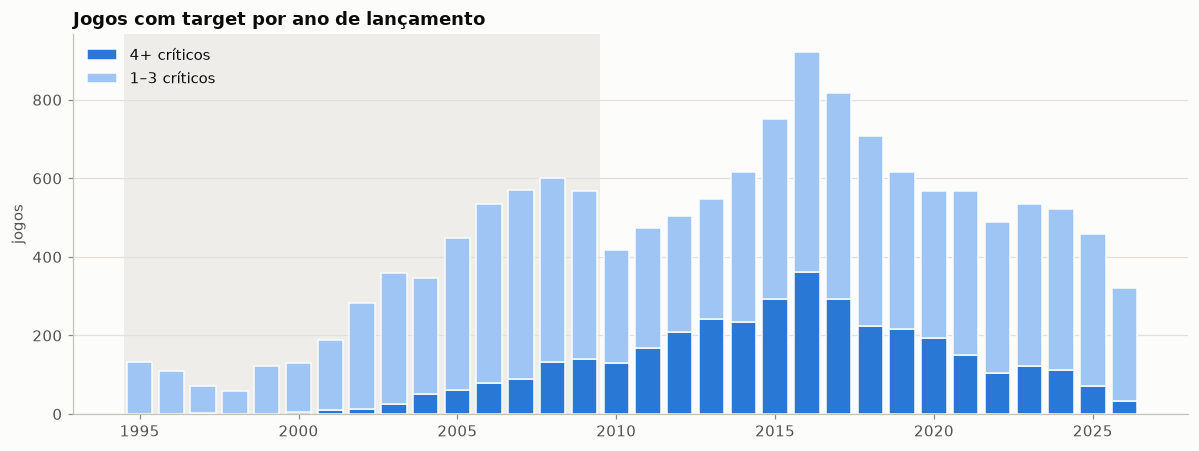

In [7]:
yr = released[released["release_year"].between(1995, 2026)]
counts = yr.groupby(["release_year", "confiavel"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(counts.index, counts[True], color=BLUE, width=0.8, edgecolor="#fcfcfb", linewidth=1,
       label=f"{MIN_CRITICS}+ críticos")
ax.bar(counts.index, counts[False], bottom=counts[True], color=BLUE_LIGHT, width=0.8,
       edgecolor="#fcfcfb", linewidth=1, label=f"1–{MIN_CRITICS - 1} críticos")
ax.axvspan(counts.index.min() - 0.5, MIN_YEAR - 0.5, color=GRID, alpha=0.5, linewidth=0, zorder=0)
ax.set_title("Jogos com target por ano de lançamento")
ax.set_ylabel("jogos"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

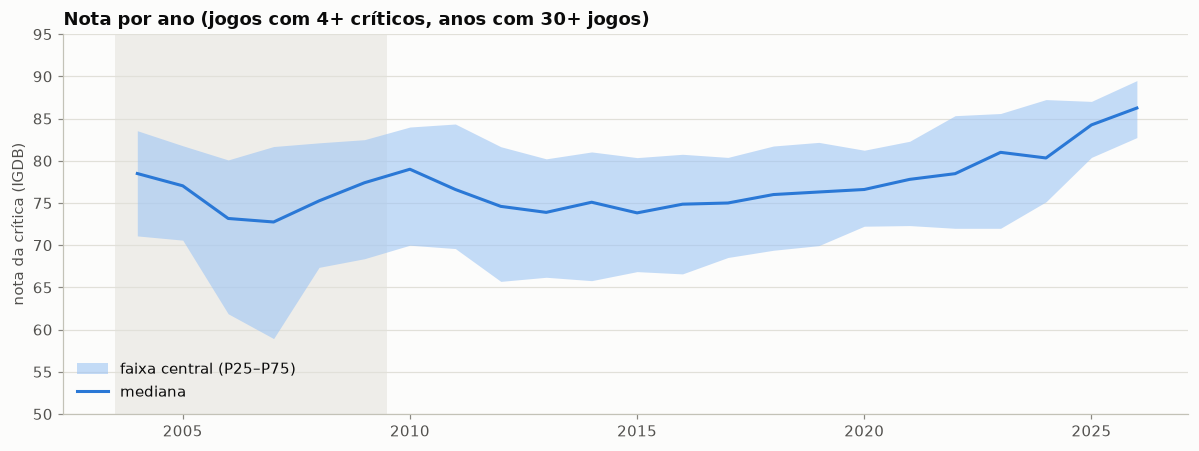

In [8]:
rel = yr[yr["confiavel"]]
q = rel.groupby("release_year")["igdb_critic_score"].quantile([0.25, 0.5, 0.75]).unstack()
q = q[rel.groupby("release_year").size() >= 30]  # anos com amostra pequena ficam de fora

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(q.index, q[0.25], q[0.75], color=BLUE_LIGHT, alpha=0.6, linewidth=0,
                label="faixa central (P25–P75)")
ax.plot(q.index, q[0.5], color=BLUE, label="mediana")
ax.axvspan(q.index.min() - 0.5, MIN_YEAR - 0.5, color=GRID, alpha=0.5, linewidth=0, zorder=0)
ax.set_ylim(50, 95)
ax.set_title(f"Nota por ano (jogos com {MIN_CRITICS}+ críticos, anos com 30+ jogos)")
ax.set_ylabel("nota da crítica (IGDB)"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

## 5. Primeiras features candidatas

### Gêneros

Um jogo pode ter vários gêneros (lista separada por `|`), então cada jogo conta em todos os
seus gêneros.

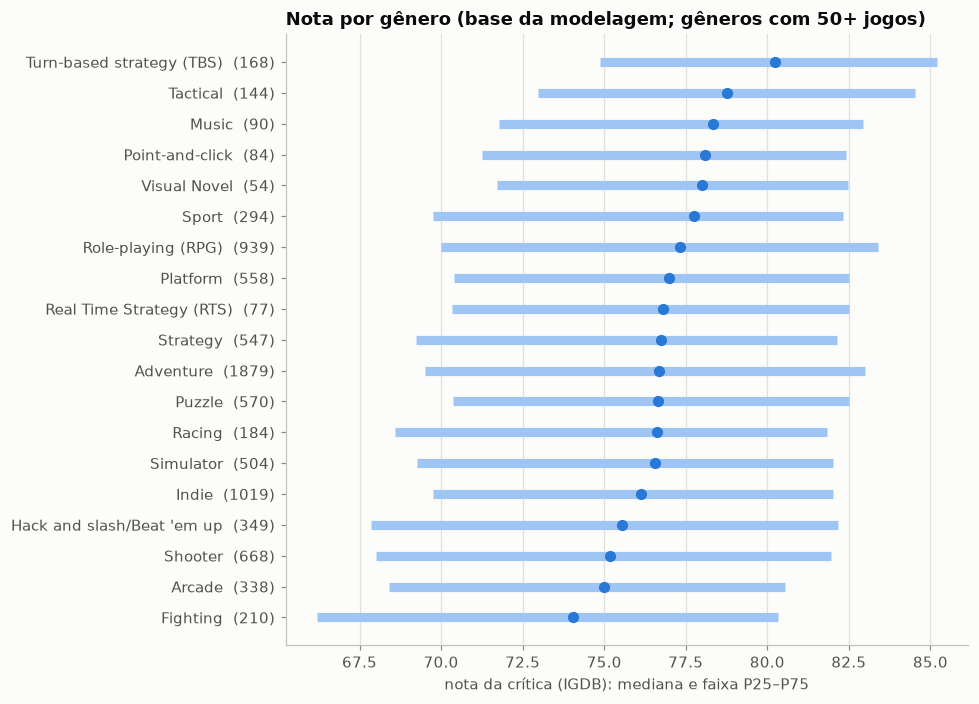

In [9]:
def explode(frame, col):
    return frame.assign(**{col: frame[col].str.split("|")}).explode(col).dropna(subset=[col])

g = explode(base, "genres")
stats = (g.groupby("genres")["igdb_critic_score"]
         .agg(jogos="size", mediana="median",
              p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75))
         .query("jogos >= 50").sort_values("mediana"))

fig, ax = plt.subplots(figsize=(9, 6.5))
y = np.arange(len(stats))
ax.hlines(y, stats["p25"], stats["p75"], color=BLUE_LIGHT, linewidth=6)
ax.scatter(stats["mediana"], y, color=BLUE, s=40, zorder=3)
ax.set_yticks(y, [f"{n}  ({j})" for n, j in zip(stats.index, stats["jogos"])])
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("nota da crítica (IGDB): mediana e faixa P25–P75")
ax.set_title("Nota por gênero (base da modelagem; gêneros com 50+ jogos)")
plt.tight_layout(); plt.show()

### Hype pré-lançamento (`hypes`)

`hypes` é o número de follows no IGDB **antes** do lançamento. Ausente não é zero: o IGDB só
começou a contar em algum momento, então jogos antigos quase nunca têm o valor.

jogos da base com hypes > 0: 1,655 de 3,157 (52%)
por ano (com hypes > 0): {2010: 7, 2011: 7, 2012: 6, 2013: 29, 2014: 89, 2015: 108, 2016: 198, 2017: 207, 2018: 174, 2019: 185, 2020: 155, 2021: 116, 2022: 88, 2023: 81, 2024: 102, 2025: 70, 2026: 33}


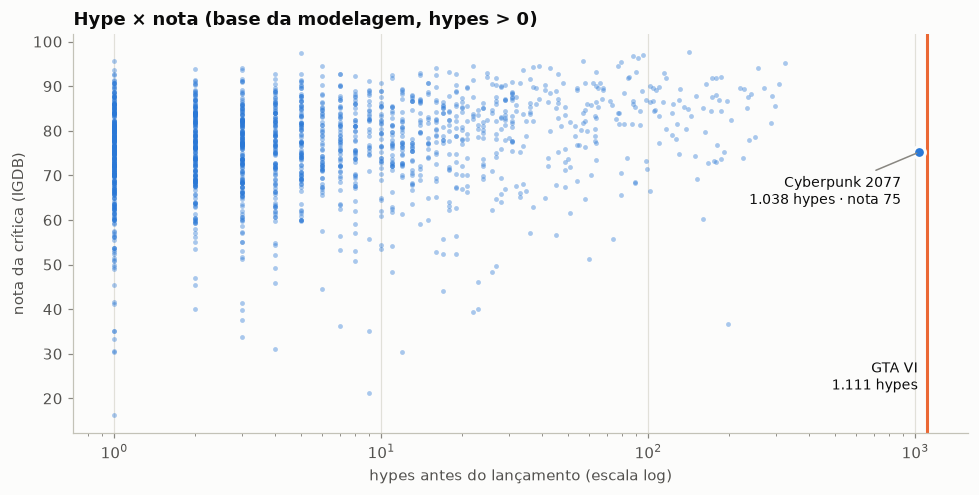

correlação de Spearman (hypes × nota): 0.24
jogos da base com mais hype que o GTA VI: 0


In [10]:
h = base[base["hypes"].fillna(0) > 0]
print(f"jogos da base com hypes > 0: {len(h):,} de {len(base):,} ({len(h)/len(base):.0%})")
print("por ano (com hypes > 0):", {int(k): int(v) for k, v in h.groupby("release_year").size().items()})

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(h["hypes"], h["igdb_critic_score"], s=10, color=BLUE, alpha=0.4, linewidths=0)
ax.set_xscale("log"); ax.grid(axis="both")
gta6 = upcoming.loc[upcoming["slug"] == "grand-theft-auto-vi", "hypes"].iloc[0]
ax.axvline(gta6, color=ORANGE, linewidth=2)
ax.text(gta6 * 0.92, 22, f"GTA VI\n{gta6:,.0f} hypes".replace(",", "."), color=INK, fontsize=9, ha="right")
top = h.nlargest(1, "hypes").iloc[0]  # o jogo da base mais próximo do GTA VI
ax.scatter([top["hypes"]], [top["igdb_critic_score"]], s=60, color=BLUE, edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.annotate(f"{top['name']}\n{top['hypes']:,.0f} hypes · nota {top['igdb_critic_score']:.0f}".replace(",", "."),
            (top["hypes"], top["igdb_critic_score"]), xytext=(-12, -34), textcoords="offset points",
            ha="right", fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=1))
ax.set_xlabel("hypes antes do lançamento (escala log)"); ax.set_ylabel("nota da crítica (IGDB)")
ax.set_title("Hype × nota (base da modelagem, hypes > 0)")
plt.tight_layout(); plt.show()

print("correlação de Spearman (hypes × nota):",
      round(h["hypes"].corr(h["igdb_critic_score"], method="spearman"), 2))
print("jogos da base com mais hype que o GTA VI:", int((h["hypes"] >= gta6).sum()))

## 6. Jogos de referência

In [11]:
ref = ["grand-theft-auto-iv", "red-dead-redemption", "grand-theft-auto-v", "red-dead-redemption-2",
       "cyberpunk-2077", "elden-ring", "starfield", "concord--1", "grand-theft-auto-vi"]
cols = ["name", "release_year", "na_base", "igdb_critic_score", "igdb_critic_n", "oc_top_avg", "mc_score",
        "hypes", "developers", "genres"]
df.assign(na_base=df["igdb_id"].isin(base["igdb_id"])).set_index("slug").loc[[s for s in ref if s in set(df["slug"])], cols].round(1)

,name,release_year,na_base,igdb_critic_score,igdb_critic_n,oc_top_avg,mc_score,hypes,developers,genres
slug,,,,,,,,,,
grand-theft-auto-iv,Grand Theft Auto IV,2008,False,88.1,8.0,95.0,98.0,NaN,Rockstar North,Adventure|Racing|Shooter
red-dead-redemption,Red Dead Redemption,2010,True,91.8,8.0,79.0,95.0,NaN,Rockstar North|Rockstar San Diego,Adventure|Role-playing (RPG)|Shooter
grand-theft-auto-v,Grand Theft Auto V,2013,True,88.1,27.0,92.0,NaN,NaN,Rockstar North,Adventure|Racing|Shooter
red-dead-redemption-2,Red Dead Redemption 2,2018,True,94.1,17.0,95.0,NaN,257.0,Rockstar Games,Adventure|Role-playing (RPG)|Shooter
cyberpunk-2077,Cyberpunk 2077,2020,True,75.2,21.0,76.0,86.0,1038.0,CD Projekt RED,Adventure|Role-playing (RPG)|Shooter
elden-ring,Elden Ring,2022,True,96.9,10.0,95.0,96.0,96.0,FromSoftware,Adventure|Role-playing (RPG)
starfield,Starfield,2023,True,85.4,10.0,84.0,83.0,136.0,Bethesda Game Studios,Adventure|Role-playing (RPG)|Shooter
concord--1,Concord,2024,True,65.2,4.0,64.0,NaN,16.0,Firewalk Studios,Adventure|Shooter
grand-theft-auto-vi,Grand Theft Auto VI,2026,False,NaN,NaN,NaN,NaN,1111.0,Rockstar Games,Adventure|Racing|Shooter


## Próximos passos

- ~~Fixar o corte mínimo de `igdb_critic_n`.~~ Feito: mais de 3 críticos, lançados depois de 2009.
- Definir o corte de treino e teste dentro da base (2010 em diante).
- Engenharia de features: listas (gêneros, plataformas, temas), cardinalidade de
  desenvolvedoras e publishers, histórico de notas sem vazamento e tratamento de `hypes`.